# **Pre-Processing Plan**

### Based on your analysis:

1. Which variables contain missing values?
2. How would you handle the missing values?
3. Which variables contain outliers?
4. Would you remove, retain or further investigate these observations?
5. Are there variables with very low variability?
6. Are there categories with very low frequencies?
7. What dataset would you deliver to the modelling stage?

### Import Packages/Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

### Read the data

In [2]:
training = pd.read_csv("../data/training.csv")

### Inspect the data

In [3]:
print(training.head(6))
training.info()

   i  y  d1  d2  d3  d4  d5  d7  d8  d9  ...  d18  x1  x2    x3  x4     x5  \
0  2  0   0   0   0   1   0   0   0   0  ...    0   4   2  0.50   1   1.69   
1  3  0   0   1   0   0   0   0   0   0  ...    0   1   3  1.00   1   6.49   
2  4  0   1   0   0   0   0   0   0   0  ...    0   3   3  1.00   2   0.69   
3  5  1   0   0   0   0   0   0   0   0  ...    0   4   1  1.00   1  17.49   
4  7  0   0   1   0   0   0   0   0   0  ...    0   4   3  0.15   1   1.59   
5  8  0   0   0   0   0   1   0   0   0  ...    1   2   3  0.75   1   2.39   

   x6  x7  x8    x9  
0  15   4   4  37.0  
1   4   2   5  36.0  
2   6   1   6  38.0  
3   1  12   3  30.0  
4   4   2   4  33.0  
5   7   6   7  22.0  

[6 rows x 28 columns]
<class 'pandas.DataFrame'>
RangeIndex: 3676 entries, 0 to 3675
Data columns (total 28 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   i       3676 non-null   int64  
 1   y       3676 non-null   int64  
 2   d1      3676 non-null   int

### Check whether the identifier is unique

In [4]:
print(len(training))
print(training["i"].nunique(dropna=False))

3676
3676


### Remove identifier

In [5]:
training = training.drop(columns="i")

### Define the `d_vars` and the `x_vars`

In [6]:
d_vars = training.filter(regex="^d").columns.tolist()
x_vars = training.filter(regex="^x").columns.tolist()
print(d_vars)
print(x_vars)

['d1', 'd2', 'd3', 'd4', 'd5', 'd7', 'd8', 'd9', 'd10', 'd11', 'd12', 'd13', 'd14', 'd15', 'd16', 'd17', 'd18']
['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9']


### Frequency and proportion of the target classes to check if the classes are balanced

In [7]:
print(training["y"].value_counts().sort_index())
print(training["y"].value_counts(normalize=True).sort_index())

y
0    2920
1     756
Name: count, dtype: int64
y
0    0.794342
1    0.205658
Name: proportion, dtype: float64


### Missing: frequency and proportion of missing observation per variable

In [8]:
print(training.isna().sum())
print(100 * training.isna().mean())

y       0
d1      0
d2      0
d3      0
d4      0
d5      0
d7      0
d8      0
d9      0
d10     0
d11     0
d12     0
d13     0
d14     0
d15     0
d16     0
d17     0
d18     0
x1      0
x2      0
x3      0
x4      0
x5      0
x6      0
x7      0
x8      0
x9     49
dtype: int64
y      0.000000
d1     0.000000
d2     0.000000
d3     0.000000
d4     0.000000
d5     0.000000
d7     0.000000
d8     0.000000
d9     0.000000
d10    0.000000
d11    0.000000
d12    0.000000
d13    0.000000
d14    0.000000
d15    0.000000
d16    0.000000
d17    0.000000
d18    0.000000
x1     0.000000
x2     0.000000
x3     0.000000
x4     0.000000
x5     0.000000
x6     0.000000
x7     0.000000
x8     0.000000
x9     1.332971
dtype: float64


### Variables with missing values

In [9]:
print(training.columns[training.isna().sum() > 0].tolist())

['x9']


### Identify rows with missing values in `x9`

In [10]:
print(np.where(training["x9"].isna())[0] + 1)
print(training[training["x9"].isna()])

[  62  109  178  213  314  391  449  579  586  867  898  919 1014 1038
 1247 1377 1496 1584 1631 1693 1715 1728 1729 1970 1995 2026 2029 2035
 2113 2140 2502 2571 2678 2804 2911 2968 3000 3046 3119 3200 3288 3310
 3438 3443 3525 3549 3554 3581 3634]
      y  d1  d2  d3  d4  d5  d7  d8  d9  d10  ...  d18  x1  x2     x3  x4  \
61    0   0   0   0   0   0   0   1   0    0  ...    0   3   4  0.695   1   
108   0   0   0   0   0   0   0   1   0    0  ...    0   5   4  0.695   1   
177   0   0   0   0   0   0   0   0   0    0  ...    0   7   1  0.700   1   
212   0   0   0   0   0   0   0   0   0    0  ...    0   4   1  0.500   1   
313   0   0   0   0   0   0   0   0   0    0  ...    0   2   1  1.000   1   
390   0   0   0   0   0   0   0   0   0    0  ...    0   3   1  0.700   1   
448   0   0   0   0   0   0   0   0   1    0  ...    0   1   1  0.700   1   
578   0   0   0   0   0   0   0   0   0    0  ...    0   3   1  0.150   1   
585   0   0   0   0   0   0   0   0   1    0  ...    0   

In [11]:
print("y among rows with missing x9:\n", training.loc[training["x9"].isna(), "y"].value_counts().to_dict())
print("share of y=1 among rows with x9 observed: %.3f" % training.loc[training["x9"].notna(), "y"].mean())

y among rows with missing x9:
 {0: 49}
share of y=1 among rows with x9 observed: 0.208


You can either (1) remove these 49 observations (rows):

`df_remove = training[training["x9"].notna()]`

or you can (2) impute the missing data with the `median()`.

Compare the strategies (1) and (2), considering that:
- (1) leads to a loss of information ; 
- (2) leads to include synthetic information and decide what you to do

### Comparison of strategies (1) remove the 49 rows vs (2) impute with the median
5-fold stratified CV. In both strategies the **test fold is always complete** (its `x9` gaps are filled with the median of the training fold), because `task.csv` also contains 30 rows with missing `x9` that must be predicted. Only the treatment of the training fold changes.

In [12]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

Xall, yall = training.drop(columns="y"), training["y"]
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, mk in {"Decision Tree": lambda: DecisionTreeClassifier(max_depth=6, random_state=42),
                 "Random Forest": lambda: RandomForestClassifier(200, n_jobs=-1, random_state=42)}.items():
    for strategy in ["(1) remove rows with missing x9", "(2) impute median"]:
        acc, f1 = [], []
        for tr_idx, te_idx in cv.split(Xall, yall):
            Xtr, ytr = Xall.iloc[tr_idx].copy(), yall.iloc[tr_idx]
            Xte, yte = Xall.iloc[te_idx].copy(), yall.iloc[te_idx]
            med = Xtr["x9"].median()                       # median from the training fold only
            if strategy.startswith("(1)"):
                keep = Xtr["x9"].notna(); Xtr, ytr = Xtr[keep], ytr[keep]
            Xtr["x9"] = Xtr["x9"].fillna(med); Xte["x9"] = Xte["x9"].fillna(med)
            pred = mk().fit(Xtr, ytr).predict(Xte)
            acc.append(accuracy_score(yte, pred)); f1.append(f1_score(yte, pred))
        rows.append((name, strategy, round(np.mean(acc), 4), round(np.mean(f1), 4)))
print(pd.DataFrame(rows, columns=["model", "strategy", "accuracy", "F1"]).to_string(index=False))

        model                        strategy  accuracy     F1
Decision Tree (1) remove rows with missing x9    0.8441 0.5599
Decision Tree               (2) impute median    0.8488 0.5643
Random Forest (1) remove rows with missing x9    0.9456 0.8626
Random Forest               (2) impute median    0.9513 0.8768


**Decision.** Removing the rows discards information and, since *all* 49 rows have `y = 0`, it also removes exactly the cases that show that a missing `x9` implies no discount. We therefore **impute the median and add a missing-value indicator** (`x9_missing`), which keeps the 3 676 observations and the signal.

### Investigate the continuous variables

                x1           x2           x3           x4           x5  \
count  3676.000000  3676.000000  3676.000000  3676.000000  3676.000000   
mean      4.030468     2.051959     0.548998     1.105550     2.580691   
std       2.000448     0.979668     0.391020     0.316893     2.781498   
min       1.000000     1.000000     0.001000     1.000000     0.390000   
25%       2.000000     1.000000     0.350000     1.000000     1.090000   
50%       4.000000     2.000000     0.500000     1.000000     1.690000   
75%       6.000000     3.000000     0.750000     1.000000     2.820000   
max       7.000000     4.000000     5.000000     3.000000    27.480000   

                x6           x7           x8           x9  
count  3676.000000  3676.000000  3676.000000  3627.000000  
mean      5.984766     8.892002     4.309576    26.316515  
std       4.768409     7.402999     1.621765    15.518175  
min       1.000000     1.000000     1.000000     1.000000  
25%       1.000000     4.000000  

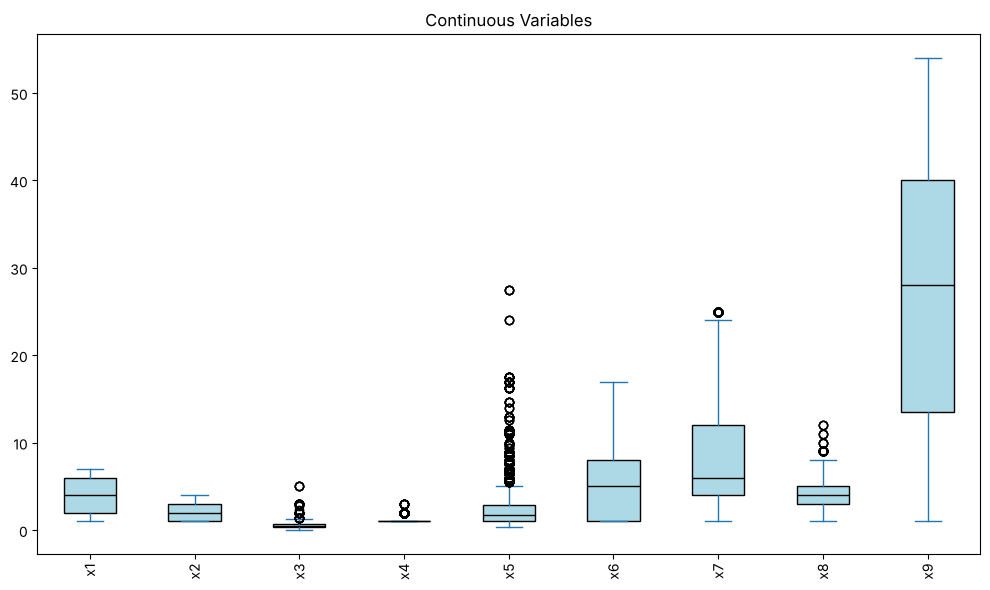

In [13]:
print(training[x_vars].describe())

training[x_vars].plot(
    kind="box",
    rot=90,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black"),
    title="Continuous Variables",
    figsize=(10, 6)
)
plt.tight_layout()
plt.show()

### If you want more detail in the boxplots

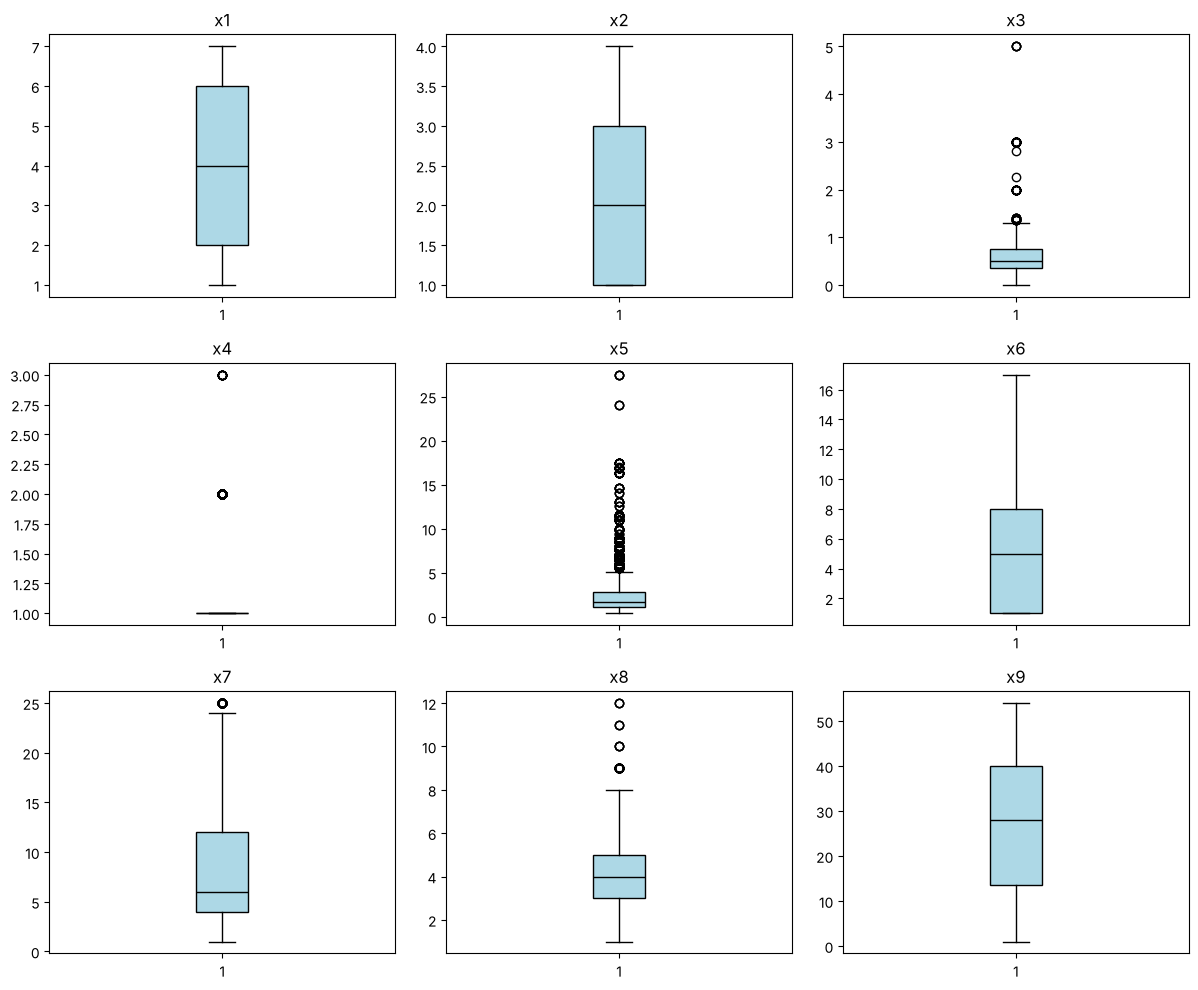

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, v in zip(axes.flat, x_vars):
    ax.boxplot(
        training[v].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor="lightblue"),
        medianprops=dict(color="black")
    )
    ax.set_title(v)
plt.tight_layout()
plt.show()

### Outliers based on the 1.5 x IQR (Tukey's) rule - example for `x1`

In [15]:
Q1 = training["x1"].quantile(0.25)
Q3 = training["x1"].quantile(0.75)
IQRv = Q3 - Q1
print(
    ((training["x1"] < (Q1 - 1.5 * IQRv)) |
     (training["x1"] > (Q3 + 1.5 * IQRv))).sum()
)

0


### Generalisation to all continuous variables

In [16]:
def count_outliers(s):
    Q1 = s.quantile(0.25)
    Q3 = s.quantile(0.75)
    IQRv = Q3 - Q1
    return ((s < (Q1 - 1.5 * IQRv)) | (s > (Q3 + 1.5 * IQRv))).sum()

outlier_count = training[x_vars].apply(count_outliers)

outlier_df = pd.DataFrame({
    "Variable": outlier_count.index,
    "N_Outliers": outlier_count.values
})
print(outlier_df)

  Variable  N_Outliers
0       x1           0
1       x2           0
2       x3          61
3       x4         377
4       x5         374
5       x6           0
6       x7         103
7       x8          55
8       x9           0


### Summary of the outliers

In [17]:
outlier_table = pd.DataFrame({
    "Variable": outlier_count.index,
    "N_Outliers": outlier_count,
    "Perc_Outliers": (100 * outlier_count / len(training)).round(2)
})

print(outlier_table)

   Variable  N_Outliers  Perc_Outliers
x1       x1           0           0.00
x2       x2           0           0.00
x3       x3          61           1.66
x4       x4         377          10.26
x5       x5         374          10.17
x6       x6           0           0.00
x7       x7         103           2.80
x8       x8          55           1.50
x9       x9           0           0.00


Variables `x4` and `x5` present the highest proportion of observations identified as outliers by the IQR rule.

Investigate whether these observations correspond to:
- data errors;
- genuine extreme values;
- highly skewed distributions;
- variables with many zero values.

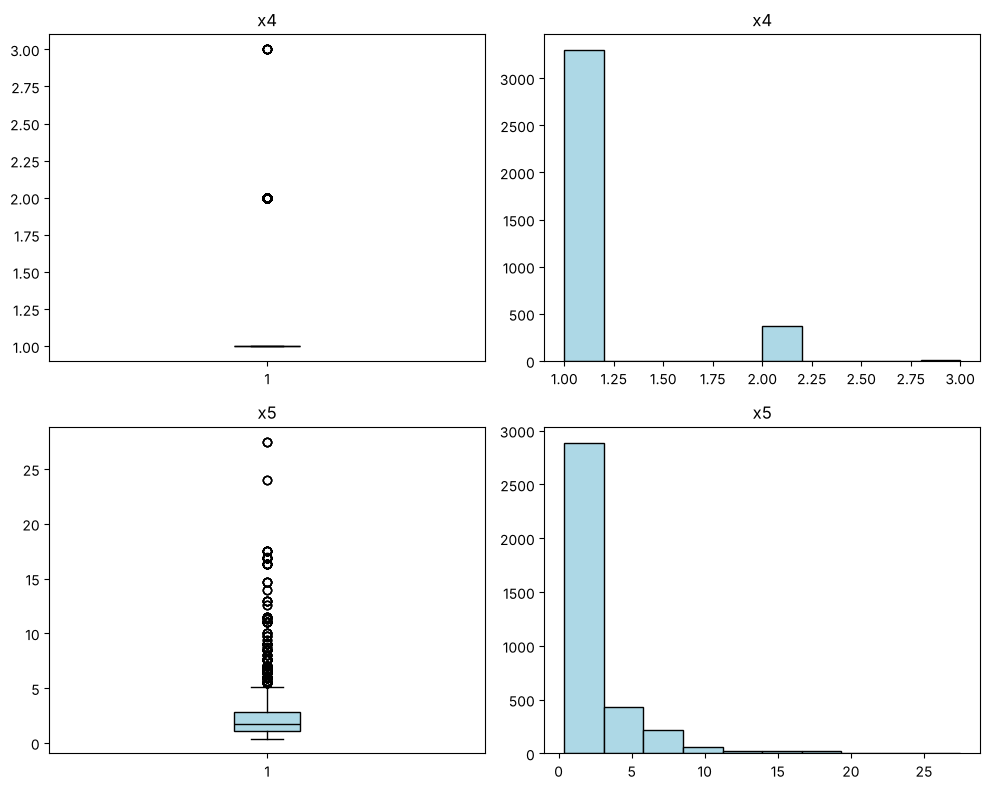

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].boxplot(
    training["x4"].dropna(),
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black")
)
axes[0, 0].set_title("x4")

axes[0, 1].hist(training["x4"].dropna(), color="lightblue", edgecolor="black")
axes[0, 1].set_title("x4")

axes[1, 0].boxplot(
    training["x5"].dropna(),
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="black")
)
axes[1, 0].set_title("x5")

axes[1, 1].hist(training["x5"].dropna(), color="lightblue", edgecolor="black")
axes[1, 1].set_title("x5")

plt.tight_layout()
plt.show()

### Discrete variables
#### Table the discrete variable to find eventual unbalanced categories

In [19]:
for v in d_vars:
    print(f"\n{v}")
    print(training[v].value_counts(normalize=True).sort_index())


d1
d1
0    0.940696
1    0.059304
Name: proportion, dtype: float64

d2
d2
0    0.860446
1    0.139554
Name: proportion, dtype: float64

d3
d3
0    0.979869
1    0.020131
Name: proportion, dtype: float64

d4
d4
0    0.829434
1    0.170566
Name: proportion, dtype: float64

d5
d5
0    0.886561
1    0.113439
Name: proportion, dtype: float64

d7
d7
0    0.984766
1    0.015234
Name: proportion, dtype: float64

d8
d8
0    0.979597
1    0.020403
Name: proportion, dtype: float64

d9
d9
0    0.8716
1    0.1284
Name: proportion, dtype: float64

d10
d10
0    0.973341
1    0.026659
Name: proportion, dtype: float64

d11
d11
0    0.939064
1    0.060936
Name: proportion, dtype: float64

d12
d12
0    0.976877
1    0.023123
Name: proportion, dtype: float64

d13
d13
0    0.932535
1    0.067465
Name: proportion, dtype: float64

d14
d14
0    0.949402
1    0.050598
Name: proportion, dtype: float64

d15
d15
0    0.97198
1    0.02802
Name: proportion, dtype: float64

d16
d16
0    0.971708
1    0.028292
Name:

Does the distribution of `y` differ across the categories?
- Rows = categories of the predictor variable
- Columns = classes of the target variable `y`

Proportions are calculated within each category:

In [20]:
for v in d_vars:
    print("\n====================")
    print("Variable:", v)
    print("====================")
    print(pd.crosstab(training[v], training["y"], normalize="index"))


Variable: d1
y          0         1
d1                    
0   0.800463  0.199537
1   0.697248  0.302752

Variable: d2
y          0         1
d2                    
0   0.801138  0.198862
1   0.752437  0.247563

Variable: d3
y          0         1
d3                    
0   0.794559  0.205441
1   0.783784  0.216216

Variable: d4
y          0         1
d4                    
0   0.803542  0.196458
1   0.749601  0.250399

Variable: d5
y          0         1
d5                    
0   0.772016  0.227984
1   0.968825  0.031175

Variable: d7
y          0         1
d7                    
0   0.794751  0.205249
1   0.767857  0.232143

Variable: d8
y          0         1
d8                    
0   0.797001  0.202999
1   0.666667  0.333333

Variable: d9
y          0         1
d9                    
0   0.780275  0.219725
1   0.889831  0.110169

Variable: d10
y           0         1
d10                    
0    0.791224  0.208776
1    0.908163  0.091837

Variable: d11
y           0         1
d1

Check if there are variables "almost" constant

In [21]:
near_constant = training[d_vars + x_vars].apply(
    lambda x: x.value_counts(normalize=True, dropna=False).max()
)

print(near_constant.sort_values(ascending=False))

d7     0.984766
d3     0.979869
d8     0.979597
d12    0.976877
d10    0.973341
d15    0.971980
d17    0.971980
d16    0.971708
d14    0.949402
d1     0.940696
d11    0.939064
d18    0.934440
d13    0.932535
x4     0.897443
d5     0.886561
d9     0.871600
d2     0.860446
d4     0.829434
x2     0.364799
x6     0.305495
x8     0.248640
x3     0.229869
x7     0.187432
x1     0.148531
x9     0.094124
x5     0.044070
dtype: float64


## **Summary** of Data Quality Issues

### Variables with missing values

In [22]:
print(training.columns[training.isna().sum() > 0].tolist())

['x9']


### Variables with outliers

In [23]:
print(outlier_table[outlier_table["N_Outliers"] > 0])

   Variable  N_Outliers  Perc_Outliers
x3       x3          61           1.66
x4       x4         377          10.26
x5       x5         374          10.17
x7       x7         103           2.80
x8       x8          55           1.50


### Variables with low variability

In [24]:
print(near_constant.sort_values(ascending=False))

d7     0.984766
d3     0.979869
d8     0.979597
d12    0.976877
d10    0.973341
d15    0.971980
d17    0.971980
d16    0.971708
d14    0.949402
d1     0.940696
d11    0.939064
d18    0.934440
d13    0.932535
x4     0.897443
d5     0.886561
d9     0.871600
d2     0.860446
d4     0.829434
x2     0.364799
x6     0.305495
x8     0.248640
x3     0.229869
x7     0.187432
x1     0.148531
x9     0.094124
x5     0.044070
dtype: float64


## **Answers to the Pre-Processing Plan**

In [25]:
low_freq = {v: round(training[v].mean() * 100, 2) for v in d_vars if training[v].mean() < 0.03}
print("1. Variables with missing values:", training.columns[training.isna().sum() > 0].tolist(), "-> x9:", int(training['x9'].isna().sum()), "rows (%.2f%%)" % (100 * training['x9'].isna().mean()))
print("3. Variables with outliers (Tukey):", outlier_table[outlier_table['N_Outliers'] > 0].set_index('Variable')['N_Outliers'].to_dict())
print("5. Almost-constant variables (most frequent value > 95%):", near_constant[near_constant > 0.95].round(3).sort_values(ascending=False).to_dict())
print("6. Binary categories with prevalence < 3%:", low_freq)
print("7. Dataset delivered:", training.shape[0], "rows x", training.shape[1] - 1, "predictors + x9_missing indicator")

1. Variables with missing values:

 ['x9'] -> x9: 49 rows (1.33%)
3. Variables with outliers (Tukey): {'x3': 61, 'x4': 377, 'x5': 374, 'x7': 103, 'x8': 55}
5. Almost-constant variables (most frequent value > 95%): {'d7': 0.985, 'd3': 0.98, 'd8': 0.98, 'd12': 0.977, 'd10': 0.973, 'd15': 0.972, 'd16': 0.972, 'd17': 0.972}
6. Binary categories with prevalence < 3%: {'d3': np.float64(2.01), 'd7': np.float64(1.52), 'd8': np.float64(2.04), 'd10': np.float64(2.67), 'd12': np.float64(2.31), 'd15': np.float64(2.8), 'd16': np.float64(2.83), 'd17': np.float64(2.8)}
7. Dataset delivered: 3676 rows x 26 predictors + x9_missing indicator


1. **Missing values:** only `x9` (49 rows, 1.33%); the same 30 gaps appear in `task.csv`. All 49 rows have `y = 0`, so the missingness is informative.
2. **Handling:** impute the training median (computed inside each training fold) **and** add the indicator `x9_missing`. The comparison above shows that removing the rows does not help and loses the signal.
3. **Outliers (Tukey 1.5 x IQR):** `x3` (61), `x4` (377), `x5` (374), `x7` (103) and `x8` (55); `x1`, `x2`, `x6` and `x9` have none.
4. **Decision:** **retain** all of them. `x5` is a highly skewed variable with genuine large values; `x4` is almost constant (IQR = 0), so every value other than 1 is flagged although 2 and 3 are legitimate categories; the extreme `x3 = 5` is plausible. Tree-based models are insensitive to them and winsorising did not improve KNN or Naive Bayes in the CV experiment of the report.
5. **Low variability:** `x4` (89.7% of the rows equal 1) and the dummies `d3`, `d7`, `d8`, `d12` (>97% zeros). They are kept: the models can ignore them and mutual information shows that a few carry almost no signal.
6. **Rare categories:** `d3`, `d7`, `d8`, `d12`, `d10`, `d15`, `d16`, `d17` (prevalence below 3%). They were not merged because, being independent binary indicators, merging them would create an artificial category.
7. **Dataset delivered to modelling:** 3 676 rows, the 26 predictors (17 `d` + 9 `x`) plus `x9_missing`, `i` removed, median-imputed, outliers untouched, standardised only for the distance-based models (KNN, SVM, MLP, K-Means, logistic regression, Naive Bayes), with an 80/20 stratified split into inner training and validation sets.